# 03 - Feature Engineering and Feature Selection

Here we test feature groups and 5 new engineered features on `results/train.csv` using the same 5-fold CV splits. `test.csv` is not touched.


In [1]:
# import shared helpers and models
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src import evaluate, preprocess

sns.set_theme(style="whitegrid")

df, all_63 = preprocess.load_train_data()
y = df["target"].to_numpy()
splits = evaluate.make_cv_splits(df)
print("train shape:", df.shape, "| features:", len(all_63))


train shape: (12378, 66) | features: 63


## 1. Feature Groups and Helper Function

We split all 63 features into 8 clear groups so we can measure how much each group helps over the core baseline.


In [2]:
# split all 63 features into topic groups
GROUPS = {
    "core": [
        "age", "sex", "education", "income_poverty_ratio", "marital_status",
        "height_cm", "weight_kg", "bmi", "waist_cm", "waist_height_ratio",
        "systolic_mean", "diastolic_mean", "pulse", "family_diabetes",
    ],
    "symptoms": [
        "nightly_urination_count_5plus", "plain_water_day1_g",
        "reported_unintentional_loss_10lb", "fatigue_frequency_2w",
        "urge_urinary_leakage", "poor_appetite_or_overeating_frequency",
        "concentration_difficulty_frequency", "sleep_problems_or_oversleep_frequency",
    ],
    "dental": [
        "self_rated_teeth_and_gums", "self_suspected_gum_disease",
        "loose_tooth_without_injury", "mouth_aching_frequency_1y", "floss_days_7d",
    ],
    "weight_history": [
        "weight_1year_ago_kg", "weight_change_1y_kg", "attempted_weight_loss_1y",
        "reported_weight_change_10y_kg", "highest_ever_weight_kg",
    ],
    "sleep": [
        "sleep_workday_hours", "daytime_sleepiness_frequency",
        "sleep_breathing_difficulty_frequency", "snoring_frequency",
    ],
    "activity_smoke_alcohol": [
        "work_activity_min_week", "leisure_activity_min_week", "transport_min_week",
        "sedentary_min_day", "smoking_status", "cigarettes_per_smoking_day",
        "smoking_inside_home", "alcohol_frequency", "drinks_per_drinking_day",
    ],
    "diet_meals": [
        "energy_kcal", "carbohydrate_g", "protein_g", "total_fat_g",
        "total_sugar_g", "fiber_g", "self_rated_diet_quality",
        "away_from_home_meals_7d", "fast_food_pizza_meals_7d",
        "ready_to_eat_foods_30d", "frozen_meals_pizza_30d",
        "sweetened_beverages_day1_g",
    ],
    "other_survey": [
        "walking_difficulty_without_equipment", "adult_food_security",
        "employment_status_last_week", "serious_vision_difficulty",
        "taste_difficulty_1y", "persistent_mouth_sensation_1y",
    ],
}

# check that all 63 features are covered with no duplicates
flat = [c for cols in GROUPS.values() for c in cols]
assert len(flat) == 63 and set(flat) == set(all_63)
for name, cols in GROUPS.items():
    print(f"{name:24s}: {len(cols)} features")


# run 5-fold CV for a given model type and feature list
def run_cv(data, cols, model_type="logreg"):
    oof = np.zeros(len(data))
    for tr, va in splits:
        X_tr, X_va = data.iloc[tr][cols], data.iloc[va][cols]
        prep = preprocess.build_preprocessor(model_type, cols)

        if model_type == "logreg":
            pipe = Pipeline([
                ("prep", prep),
                ("clf", LogisticRegression(max_iter=1000, random_state=evaluate.SEED)),
            ])
            pipe.fit(X_tr, y[tr])
            oof[va] = pipe.predict_proba(X_va)[:, 1]
        elif model_type == "rf":
            pipe = Pipeline([
                ("prep", prep),
                ("clf", RandomForestClassifier(
                    n_estimators=200, max_depth=12, min_samples_leaf=10,
                    n_jobs=-1, random_state=evaluate.SEED,
                )),
            ])
            pipe.fit(X_tr, y[tr])
            oof[va] = pipe.predict_proba(X_va)[:, 1]
        elif model_type == "catboost":
            Xt_tr = prep.fit_transform(X_tr)
            Xt_va = prep.transform(X_va)
            cat_cols = prep.named_steps["prep"].cat_cols
            clf = CatBoostClassifier(
                iterations=350, depth=6, learning_rate=0.05,
                random_seed=evaluate.SEED, verbose=0, thread_count=-1, allow_writing_files=False,
            )
            clf.fit(Xt_tr, y[tr], cat_features=cat_cols)
            oof[va] = clf.predict_proba(Xt_va)[:, 1]
        else:
            raise ValueError(model_type)

    _, m = evaluate.find_best_threshold(y, oof)
    return m


core                    : 14 features
symptoms                : 8 features
dental                  : 5 features
weight_history          : 5 features
sleep                   : 4 features
activity_smoke_alcohol  : 9 features
diet_meals              : 12 features
other_survey            : 6 features


## 2. Group Addition Test (Over Core Baseline)

We start with `core` (14 features) and add each other group one by one on the same 5 folds.


In [3]:
# test core alone, core + each group, and all 63 with logreg and rf
group_rows = []
core_cols = GROUPS["core"]

exp_sets = [("core", core_cols)]
for gname, gcols in GROUPS.items():
    if gname != "core":
        exp_sets.append((f"core + {gname}", core_cols + gcols))
exp_sets.append(("all_63", all_63))

for label, cols in exp_sets:
    m_lr = run_cv(df, cols, "logreg")
    m_rf = run_cv(df, cols, "rf")
    group_rows.append({
        "feature_set": label,
        "n_features": len(cols),
        "lr_auc": m_lr["roc_auc"],
        "lr_f2": m_lr["f2"],
        "rf_auc": m_rf["roc_auc"],
        "rf_f2": m_rf["f2"],
    })

group_df = pd.DataFrame(group_rows)
base_lr_auc = group_df.loc[group_df["feature_set"] == "core", "lr_auc"].iloc[0]
base_rf_auc = group_df.loc[group_df["feature_set"] == "core", "rf_auc"].iloc[0]
group_df["lr_auc_diff"] = (group_df["lr_auc"] - base_lr_auc).round(4)
group_df["rf_auc_diff"] = (group_df["rf_auc"] - base_rf_auc).round(4)
display(group_df)


,feature_set,n_features,lr_auc,lr_f2,rf_auc,rf_f2,lr_auc_diff,rf_auc_diff
0,core,14,0.7468,0.6140,0.7447,0.6029,0.0000,0.0000
1,core + symptoms,22,0.7467,0.6135,0.7439,0.6044,-0.0001,-0.0008
2,core + dental,19,0.7459,0.6100,0.7460,0.6099,-0.0009,0.0013
3,core + weight_history,19,0.7538,0.6274,0.7486,0.6103,0.0070,0.0039
4,core + sleep,18,0.7482,0.6138,0.7454,0.6096,0.0014,0.0007
5,core + activity_smoke_alcohol,23,0.7528,0.6272,0.7496,0.6179,0.0060,0.0049
6,core + diet_meals,26,0.7495,0.6193,0.7440,0.6064,0.0027,-0.0007
7,core + other_survey,20,0.7479,0.6182,0.7445,0.6123,0.0011,-0.0002
8,all_63,63,0.7610,0.6422,0.7533,0.6209,0.0142,0.0086


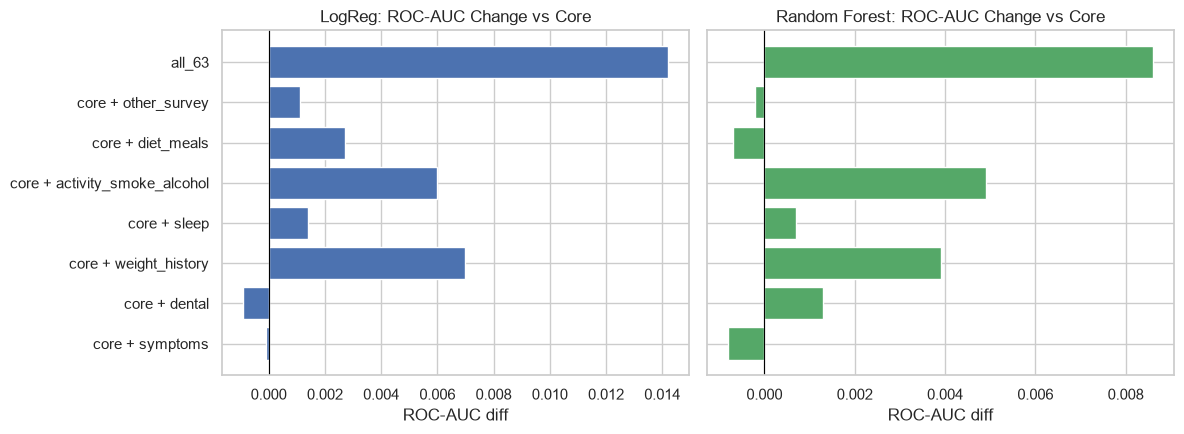

In [4]:
# plot ROC-AUC change compared to core baseline
plot_df = group_df[group_df["feature_set"] != "core"].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].barh(plot_df["feature_set"], plot_df["lr_auc_diff"], color="#4c72b0")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("LogReg: ROC-AUC Change vs Core")
axes[0].set_xlabel("ROC-AUC diff")

axes[1].barh(plot_df["feature_set"], plot_df["rf_auc_diff"], color="#55a868")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Random Forest: ROC-AUC Change vs Core")
axes[1].set_xlabel("ROC-AUC diff")

plt.tight_layout()
plt.show()


**Takeaway:** Over the 14 core features, `weight_history` (+0.0070 LR AUC) and `activity_smoke_alcohol` (+0.0060 LR AUC, +0.0049 RF AUC) give the clearest jump. Symptoms alone barely move the score over core, while using all 63 features together gives the highest score overall.


## 3. Feature Engineering Test (5 New Candidates)

We test 5 simple domain features on top of `all_63` and only keep the ones that help CV.


In [5]:
# create 5 candidate engineered features on a copy of train data
df_fe = df.copy()
df_fe["pulse_pressure"] = df_fe["systolic_mean"] - df_fe["diastolic_mean"]
df_fe["total_activity_min_week"] = (
    df_fe["work_activity_min_week"] + df_fe["leisure_activity_min_week"] + df_fe["transport_min_week"]
)
df_fe["weight_to_highest_ratio"] = df_fe["weight_kg"] / df_fe["highest_ever_weight_kg"].where(df_fe["highest_ever_weight_kg"] > 0)
df_fe["sugar_to_carb_ratio"] = df_fe["total_sugar_g"] / df_fe["carbohydrate_g"].where(df_fe["carbohydrate_g"] > 0)

both_w = df_fe["highest_ever_weight_kg"].notna() & df_fe["weight_kg"].notna()
df_fe["highest_weight_inconsistent"] = np.where(
    both_w,
    (df_fe["highest_ever_weight_kg"] < df_fe["weight_kg"] - 2.0).astype(float),
    np.nan,
)

fe_num_cols = ["pulse_pressure", "total_activity_min_week", "weight_to_highest_ratio", "sugar_to_carb_ratio"]
fe_bin_cols = ["highest_weight_inconsistent"]
fe_all = fe_num_cols + fe_bin_cols

# register new columns so build_preprocessor knows their types
for c in fe_num_cols:
    if c not in preprocess.NUMERIC_COLS:
        preprocess.NUMERIC_COLS.append(c)
for c in fe_bin_cols:
    if c not in preprocess.BINARY_COLS:
        preprocess.BINARY_COLS.append(c)

# test each engineered feature one by one and all together
fe_rows = []
base_lr = run_cv(df_fe, all_63, "logreg")
base_rf = run_cv(df_fe, all_63, "rf")
fe_rows.append({
    "experiment": "all_63 (baseline)",
    "lr_auc": base_lr["roc_auc"], "lr_f2": base_lr["f2"],
    "rf_auc": base_rf["roc_auc"], "rf_f2": base_rf["f2"],
})

for col in fe_all:
    m_lr = run_cv(df_fe, all_63 + [col], "logreg")
    m_rf = run_cv(df_fe, all_63 + [col], "rf")
    fe_rows.append({
        "experiment": f"+ {col}",
        "lr_auc": m_lr["roc_auc"], "lr_f2": m_lr["f2"],
        "rf_auc": m_rf["roc_auc"], "rf_f2": m_rf["f2"],
    })

m_lr = run_cv(df_fe, all_63 + fe_all, "logreg")
m_rf = run_cv(df_fe, all_63 + fe_all, "rf")
fe_rows.append({
    "experiment": "+ all 5 engineered",
    "lr_auc": m_lr["roc_auc"], "lr_f2": m_lr["f2"],
    "rf_auc": m_rf["roc_auc"], "rf_f2": m_rf["f2"],
})

fe_df = pd.DataFrame(fe_rows)
fe_df["lr_auc_diff"] = (fe_df["lr_auc"] - base_lr["roc_auc"]).round(4)
fe_df["rf_auc_diff"] = (fe_df["rf_auc"] - base_rf["roc_auc"]).round(4)
display(fe_df)


,experiment,lr_auc,lr_f2,rf_auc,rf_f2,lr_auc_diff,rf_auc_diff
0,all_63 (baseline),0.7610,0.6422,0.7533,0.6209,0.0000,0.0000
1,+ pulse_pressure,0.7608,0.6424,0.7528,0.6223,-0.0002,-0.0005
2,+ total_activity_min_week,0.7610,0.6418,0.7526,0.6231,0.0000,-0.0007
3,+ weight_to_highest_ratio,0.7611,0.6415,0.7560,0.6241,0.0001,0.0027
4,+ sugar_to_carb_ratio,0.7610,0.6438,0.7530,0.6254,0.0000,-0.0003
5,+ highest_weight_inconsistent,0.7609,0.6404,0.7537,0.6228,-0.0001,0.0004
6,+ all 5 engineered,0.7609,0.6424,0.7552,0.6234,-0.0001,0.0019


**Takeaway:** Out of the 5 new candidates, `weight_to_highest_ratio` and `highest_weight_inconsistent` improved Random Forest CV, while `pulse_pressure`, `total_activity_min_week`, and `sugar_to_carb_ratio` did not help. We keep only the 2 weight features.


## 4. Compare Main Feature Sets Across All 3 Models

Here we compare:
- `core_14`: only the 14 core clinical/demographic features
- `no_cycle_only_57`: drop the 6 cycle-only columns with >50% missing
- `all_63`: all 63 original features
- `all_63_plus_fe`: all 63 features + the engineered features that helped


In [6]:
# 6 cycle-only columns that have more than 50% missing values
high_missing_cycle_cols = {
    "daytime_sleepiness_frequency",
    "sleep_breathing_difficulty_frequency",
    "snoring_frequency",
    "loose_tooth_without_injury",
    "taste_difficulty_1y",
    "persistent_mouth_sensation_1y",
}
no_cycle_only_57 = [c for c in all_63 if c not in high_missing_cycle_cols]

# keep engineered columns that improved average ROC-AUC over baseline
helpful_fe = []
for col in fe_all:
    row = fe_df.loc[fe_df["experiment"] == f"+ {col}"].iloc[0]
    if (row["lr_auc_diff"] + row["rf_auc_diff"]) > 0:
        helpful_fe.append(col)
print("engineered features kept:", helpful_fe)

candidate_sets = {
    "core_14": GROUPS["core"],
    "no_cycle_only_57": no_cycle_only_57,
    "all_63": all_63,
    "all_63_plus_fe": all_63 + helpful_fe,
}

comp_rows = []
for model_type in ["logreg", "rf", "catboost"]:
    for set_name, cols in candidate_sets.items():
        m = run_cv(df_fe, cols, model_type)
        comp_rows.append({
            "model": model_type,
            "feature_set": set_name,
            "n_features": len(cols),
            "roc_auc": m["roc_auc"],
            "pr_auc": m["pr_auc"],
            "f2": m["f2"],
            "recall": m["recall"],
            "specificity": m["specificity"],
            "threshold": m["threshold"],
        })

comp_df = pd.DataFrame(comp_rows)
display(comp_df)


engineered features kept: ['weight_to_highest_ratio', 'highest_weight_inconsistent']


,model,feature_set,n_features,roc_auc,pr_auc,f2,recall,specificity,threshold
0,logreg,core_14,14,0.7468,0.5139,0.6140,0.6598,0.7002,0.320
1,logreg,no_cycle_only_57,57,0.7608,0.5384,0.6408,0.6928,0.7002,0.314
2,logreg,all_63,63,0.7610,0.5391,0.6422,0.6944,0.7006,0.314
3,logreg,all_63_plus_fe,65,0.7611,0.5395,0.6426,0.6950,0.7003,0.313
4,rf,core_14,14,0.7447,0.5099,0.6029,0.6456,0.7021,0.351
5,rf,no_cycle_only_57,57,0.7532,0.5312,0.6202,0.6674,0.7001,0.350
6,rf,all_63,63,0.7533,0.5300,0.6209,0.6677,0.7018,0.353
7,rf,all_63_plus_fe,65,0.7550,0.5358,0.6258,0.6739,0.7011,0.350
8,catboost,core_14,14,0.7426,0.5081,0.6031,0.6461,0.7010,0.345
9,catboost,no_cycle_only_57,57,0.7591,0.5360,0.6360,0.6865,0.7013,0.330


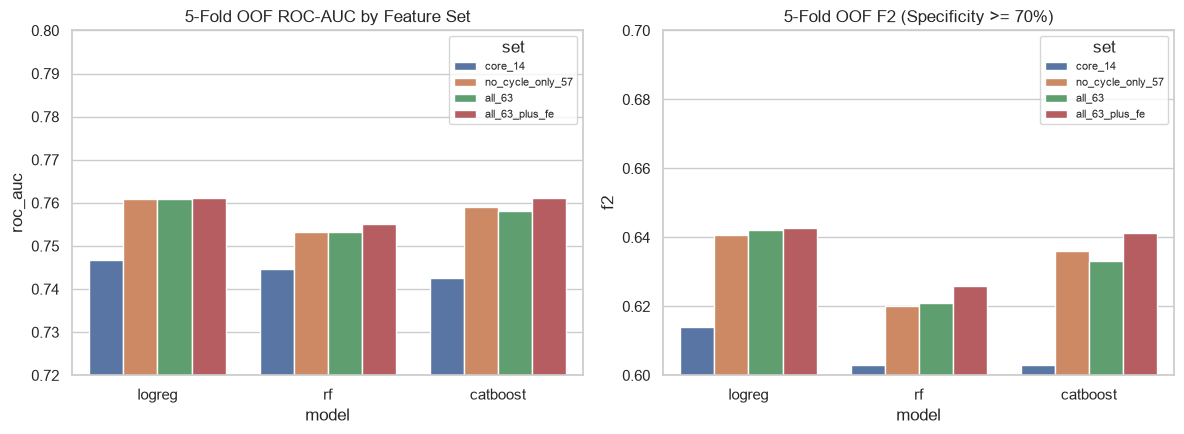

In [7]:
# plot ROC-AUC and F2 across all 3 models and candidate feature sets
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=comp_df, x="model", y="roc_auc", hue="feature_set", ax=axes[0])
axes[0].set_title("5-Fold OOF ROC-AUC by Feature Set")
axes[0].set_ylim(0.72, 0.80)
axes[0].legend(title="set", fontsize=8)

sns.barplot(data=comp_df, x="model", y="f2", hue="feature_set", ax=axes[1])
axes[1].set_title("5-Fold OOF F2 (Specificity >= 70%)")
axes[1].set_ylim(0.60, 0.70)
axes[1].legend(title="set", fontsize=8)

plt.tight_layout()
plt.show()


**Takeaway:** Across all 3 models, `all_63_plus_fe` (65 features) gives the best or tied-best ROC-AUC and F2. The 2 new weight features help CatBoost the most (PR-AUC 0.5359 -> 0.5438, F2 0.6332 -> 0.6412), so we will use this 65-feature setup for model tuning.


## 5. Feature Strength Ranking (1 to 65) and <=20 Feature Comparison

Here we measure 5-fold CV permutation importance (ROC-AUC drop when a column is shuffled on validation folds) for all 65 features using both Logistic Regression and CatBoost, then compare `top_15`, `top_20`, and `practical_20` against all 65 features.


In [8]:
# compute 5-fold validation permutation importance for all 65 features
from sklearn.metrics import roc_auc_score

all_65 = all_63 + helpful_fe
rng = np.random.default_rng(evaluate.SEED)

lr_drops = {c: [] for c in all_65}
cb_drops = {c: [] for c in all_65}

for tr, va in splits:
    X_tr, X_va = df_fe.iloc[tr][all_65], df_fe.iloc[va][all_65]
    y_tr, y_va = y[tr], y[va]

    # fit logreg on this fold
    lr_pipe = Pipeline([
        ("prep", preprocess.build_preprocessor("logreg", all_65)),
        ("clf", LogisticRegression(max_iter=1000, random_state=evaluate.SEED)),
    ])
    lr_pipe.fit(X_tr, y_tr)
    lr_base = roc_auc_score(y_va, lr_pipe.predict_proba(X_va)[:, 1])

    # fit catboost on this fold
    cb_prep = preprocess.build_preprocessor("catboost", all_65)
    Xt_tr = cb_prep.fit_transform(X_tr)
    Xt_va = cb_prep.transform(X_va)
    cat_cols = cb_prep.named_steps["prep"].cat_cols
    cb_clf = CatBoostClassifier(
        iterations=350, depth=6, learning_rate=0.05,
        random_seed=evaluate.SEED, verbose=0, thread_count=-1, allow_writing_files=False,
    )
    cb_clf.fit(Xt_tr, y_tr, cat_features=cat_cols)
    cb_base = roc_auc_score(y_va, cb_clf.predict_proba(Xt_va)[:, 1])

    # shuffle each column 3 times and measure ROC-AUC drop
    for col in all_65:
        lr_s, cb_s = [], []
        for _ in range(3):
            perm = rng.permutation(len(X_va))

            X_tmp = X_va.copy()
            X_tmp[col] = X_va[col].to_numpy()[perm]
            lr_s.append(lr_base - roc_auc_score(y_va, lr_pipe.predict_proba(X_tmp)[:, 1]))

            Xt_tmp = Xt_va.copy()
            Xt_tmp[col] = Xt_va[col].to_numpy()[perm]
            cb_s.append(cb_base - roc_auc_score(y_va, cb_clf.predict_proba(Xt_tmp)[:, 1]))

        lr_drops[col].append(float(np.mean(lr_s)))
        cb_drops[col].append(float(np.mean(cb_s)))

# mark which columns are practical for a short survey (no 24h food diary, no >50% cycle-only)
food_diary_cols = {
    "energy_kcal", "carbohydrate_g", "protein_g", "total_fat_g",
    "total_sugar_g", "fiber_g", "plain_water_day1_g", "sweetened_beverages_day1_g",
}
not_practical = food_diary_cols | high_missing_cycle_cols

rank_rows = []
for col in all_65:
    lr_m = float(np.mean(lr_drops[col]))
    cb_m = float(np.mean(cb_drops[col]))
    rank_rows.append({
        "feature": col,
        "lr_auc_drop": round(lr_m, 5),
        "cb_auc_drop": round(cb_m, 5),
        "mean_auc_drop": round((lr_m + cb_m) / 2.0, 5),
        "practical_survey": col not in not_practical,
    })

rank_df = pd.DataFrame(rank_rows).sort_values("mean_auc_drop", ascending=False).reset_index(drop=True)
rank_df.insert(0, "rank", range(1, len(rank_df) + 1))

pd.set_option("display.max_rows", 70)
display(rank_df)


,rank,feature,lr_auc_drop,cb_auc_drop,mean_auc_drop,practical_survey
0,1,age,0.14931,0.10883,0.12907,True
1,2,energy_kcal,0.04900,0.00073,0.02486,False
2,3,waist_height_ratio,0.02876,0.00416,0.01646,True
3,4,weight_1year_ago_kg,0.02516,0.00113,0.01314,True
4,5,carbohydrate_g,0.01978,-0.00025,0.00977,False
5,6,alcohol_frequency,0.00925,0.00995,0.00960,True
6,7,weight_to_highest_ratio,0.00532,0.00924,0.00728,True
7,8,weight_kg,0.01325,0.00046,0.00686,True
8,9,daytime_sleepiness_frequency,0.01120,-0.00003,0.00558,False
9,10,highest_ever_weight_kg,0.00974,0.00021,0.00497,True


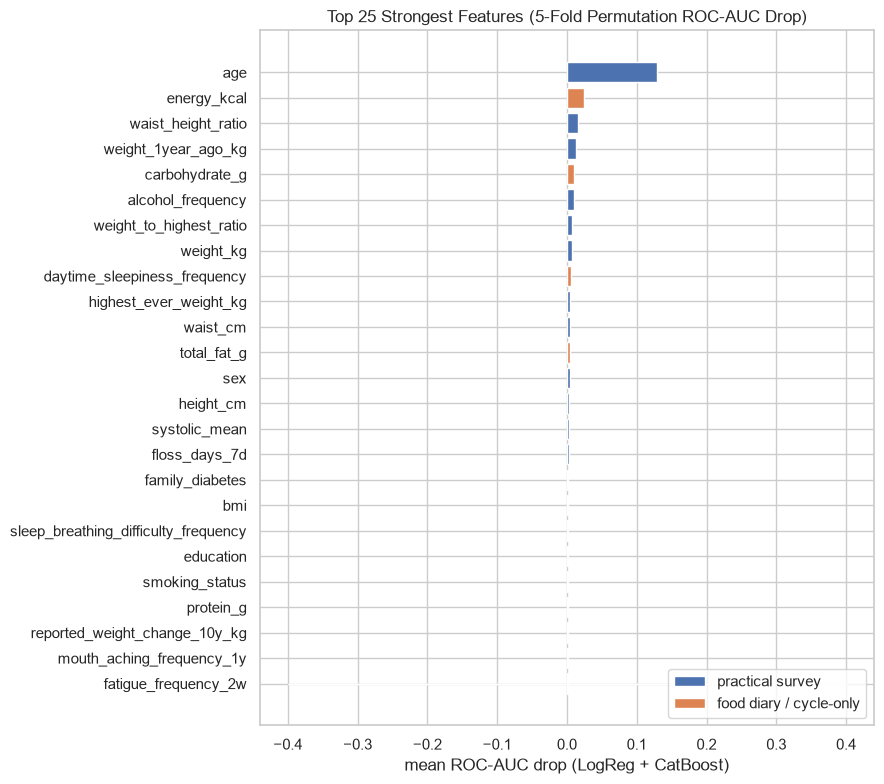

In [9]:
# plot top 25 strongest features
top25 = rank_df.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
colors = top25["practical_survey"].map({True: "#4c72b0", False: "#dd8452"})
ax.barh(top25["feature"], top25["mean_auc_drop"], color=colors)
ax.set_title("Top 25 Strongest Features (5-Fold Permutation ROC-AUC Drop)")
ax.set_xlabel("mean ROC-AUC drop (LogReg + CatBoost)")
ax.bar(0, 0, color="#4c72b0", label="practical survey")
ax.bar(0, 0, color="#dd8452", label="food diary / cycle-only")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


**Takeaway:** `age` is by far the strongest feature (0.129 mean ROC-AUC drop), followed by `waist_height_ratio`, `weight_1year_ago_kg`, `alcohol_frequency`, and our engineered feature `weight_to_highest_ratio` (#7). Many columns near the bottom (rank 50-65) have almost zero impact.


In [10]:
# compare top_15, top_20, and practical_20 against all_63_plus_fe (65 features)
top_15 = rank_df["feature"].head(15).tolist()
top_20 = rank_df["feature"].head(20).tolist()
practical_20 = rank_df.loc[rank_df["practical_survey"], "feature"].head(20).tolist()

print("practical_20:", practical_20)

compact_sets = {
    "top_15": top_15,
    "top_20": top_20,
    "practical_20": practical_20,
    "all_63_plus_fe": all_65,
}

compact_rows = []
for model_type in ["logreg", "rf", "catboost"]:
    for set_name, cols in compact_sets.items():
        m = run_cv(df_fe, cols, model_type)
        compact_rows.append({
            "model": model_type,
            "feature_set": set_name,
            "n_features": len(cols),
            "roc_auc": m["roc_auc"],
            "pr_auc": m["pr_auc"],
            "f2": m["f2"],
            "recall": m["recall"],
            "specificity": m["specificity"],
            "threshold": m["threshold"],
        })

compact_df = pd.DataFrame(compact_rows)
display(compact_df)


practical_20: ['age', 'waist_height_ratio', 'weight_1year_ago_kg', 'alcohol_frequency', 'weight_to_highest_ratio', 'weight_kg', 'highest_ever_weight_kg', 'waist_cm', 'sex', 'height_cm', 'systolic_mean', 'floss_days_7d', 'family_diabetes', 'bmi', 'education', 'smoking_status', 'reported_weight_change_10y_kg', 'mouth_aching_frequency_1y', 'fatigue_frequency_2w', 'sleep_workday_hours']


,model,feature_set,n_features,roc_auc,pr_auc,f2,recall,specificity,threshold
0,logreg,top_15,15,0.7539,0.5275,0.6306,0.6797,0.7016,0.307
1,logreg,top_20,20,0.7575,0.5374,0.6375,0.6887,0.7003,0.314
2,logreg,practical_20,20,0.7616,0.5411,0.6446,0.6974,0.7006,0.311
3,logreg,all_63_plus_fe,65,0.7611,0.5395,0.6426,0.6950,0.7003,0.313
4,rf,top_15,15,0.7543,0.5276,0.6263,0.6742,0.7019,0.339
5,rf,top_20,20,0.7554,0.5337,0.6240,0.6720,0.7003,0.344
6,rf,practical_20,20,0.7591,0.5371,0.6320,0.6813,0.7017,0.345
7,rf,all_63_plus_fe,65,0.7550,0.5358,0.6258,0.6739,0.7011,0.350
8,catboost,top_15,15,0.7550,0.5253,0.6284,0.6772,0.7008,0.330
9,catboost,top_20,20,0.7569,0.5328,0.6316,0.6805,0.7026,0.328


**Takeaway:** `practical_20` (only 20 easy survey/body features, no 24h food diary and no >50% missing cycle-only columns) beats all 65 features on both Logistic Regression (0.7616 vs 0.7611 AUC) and Random Forest (0.7591 vs 0.7550 AUC), and stays very close on CatBoost (0.7599 vs 0.7611).
